## Explorations into Biogeochemical Models

A 1D water column (surface $z=0$ down to $z=-250$ m) with nutrients $N$ and phytoplankton $P$.
We start from the Hodges & Rudnick (2004) NP model and add one process at a time:

1. **Base model**
2. **+ Sinking**
3. **+ Self-shading**
4. **+ Surface nutrient forcing**

### Base Model

We use the model proposed by Hodges & Rudnick (2004) as our base:
$$
\begin{align}
    \frac{\partial N}{\partial t} &= -\mu(N,P,z) + \frac{\partial}{\partial z}\big( \kappa\frac{\partial N}{\partial z} \big), \\
    \frac{\partial P}{\partial t} &= \mu(N,P,z) + \frac{\partial}{\partial z}\big( \kappa\frac{\partial P}{\partial z} \big),
\end{align}
\qquad
\mu(N,P,z) = \underbrace{GNPe^{-K|z|}}_{\text{growth}} - \underbrace{DP}_{\text{death}},
$$
with no flux of $N$ or $P$ at the surface, and $N=1$, $P = 0$ at the bottom.
Where:
- $N$: nutrients, $P$: phytoplankton
- $\mu(N,P,z) = \text{growth}-\text{death}$ encapsulates:
    - Net rate at which nitrogen flows from $N$ to $P$
    - Net rate of total phytoplankton growth minus all losses (death and grazing by zooplankton included)
- $G$: growth rate, $D$: death rate (natural mortality, zooplankton grazing)
- $\kappa$: turbulent diffusivity
- $K$: light attenuation coefficient (Beer-Lambert, light intensity: $I(z)=I_0e^{-K|z|}$)

#### Model Parameters:
- $G = 20\ \text{day}^{-1}$ growth rate (realized growth rate $GN e^{-K|z|}$ much smaller), $D = 0.1\ \text{day}^{-1}$ death rate, $K = 0.05\ \text{m}^{-1}$ light attenuation, $\kappa = 10^{-4}\ \text{m}^2/\text{s}$ turbulent diffusivity
- Initial condition: $N = P = 0.5$ everywhere

Growth slower time-scale than death

In [15]:
# imports and helper funcs
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import params

%matplotlib ipympl

import sim, plots
from forcings import sine, pulses, ramp, add, seasonal_flux, constant

plt.rcParams["figure.figsize"] = (8, 4)
trapz = getattr(np, "trapezoid", None) or np.trapz       # depth integral

def dcm(res):
    """Depth and value of the phytoplankton maximum at every saved time."""
    k = res.P.argmax(axis=1)
    return res.depth[k], res.P[np.arange(len(k)), k]
    
# --- Plotting & animation ---
def draw_frame(frame, N, P, z):
    ax.clear()
    ax.plot(N[frame], z, label="Nutrients (N)")
    ax.plot(P[frame], z, label="Phytoplankton (P)")
    days = frame * 100 * 900 / 86400
    ax.set_title(f"Time: {days:.1f} Days")
    ax.set_xlabel("Concentration")
    ax.set_ylabel("Depth (m)")
    ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.5)

In [16]:
base = sim.run(N_BOT_BC = "dirichlet")

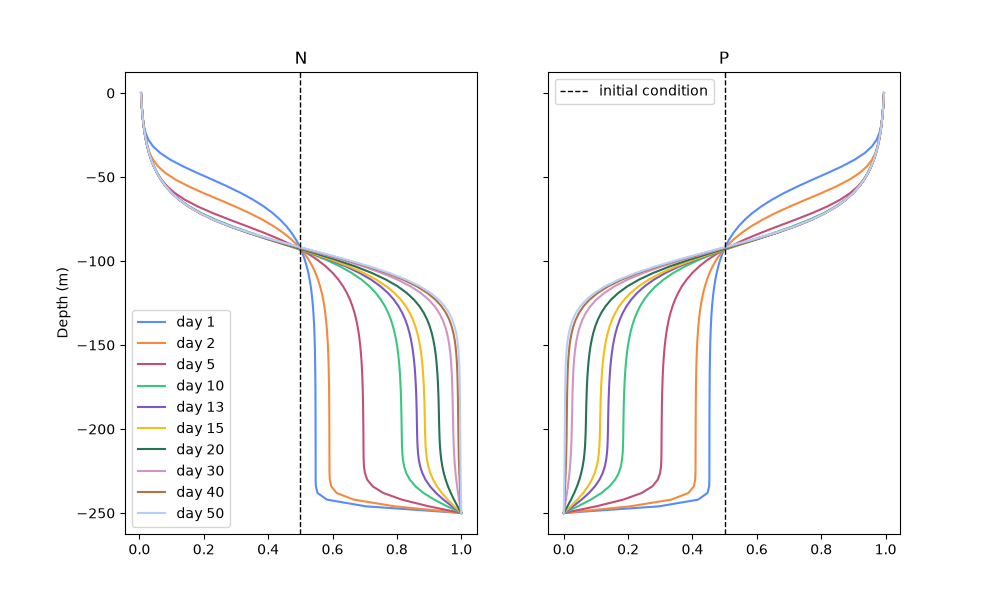

In [17]:
with plt.rc_context({"figure.figsize": (10, 6)}):
    fig, ax = plots.profiles(base, [1, 2, 5, 10, 13, 15, 20, 30, 40, 50])
    ax[0].axvline(params.N_INIT, color="k", ls="--", lw=1)
    ax[1].axvline(params.P_INIT, color="k", ls="--", lw=1, label="initial condition")
    ax[1].legend()
plt.show()

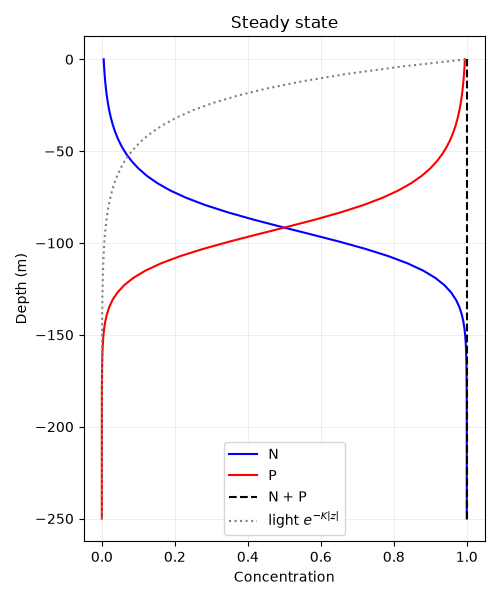

In [18]:
fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(base.N[-1], base.depth, label="N", color="blue")
ax.plot(base.P[-1], base.depth, label="P", color="red")
ax.plot(base.N[-1] + base.P[-1], base.depth, "k--", label="N + P")
ax.plot(np.exp(params.LIGHT_ATTENUATION * base.depth), base.depth, ":", color="gray", label="light $e^{-K|z|}$")
ax.set(title=f"Steady state", xlabel="Concentration", ylabel="Depth (m)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Takeaways**
- Decays to a steady state
- At steady state, $P$ is largest at the surface: no deep maximum. Near the top, nutrients are used up ($N \to 0$); below ~100 m it is too dark for growth to beat death, so deep $P$ decays at the death rate.
- $N+P=1$ at every depth and time - wherever $P$ is largest, $N$ is smallest, vice versa.


A decent toy model, but oceans often show a *subsurface* maximum (DCM/DBM). What's missing?

**Why there's no deep maximum.** Because $N + P = 1$ everywhere, phytoplankton can only live where nutrients have been used up, and that is always the sunlit surface. Independent of parameter choices. The base model is useful for understanding equilibrium behaviour of a basic model but real oceans often show a *subsurface* maximum (a DCM/DBM) and additional physics must be included.

### Phytoplankton sinking

One of the main aims of Hodges & Rudnick (2004) is to investigate possible mechanisms that cause the DCM (deep chlorophyll maximum) and DBM (deep biomass maximum) phenomena which is often seen in oceans. They conclude that phytoplankton sinking is critical to the formation of deep maxima in biomass in these models. For sinking, they add a sinking term to the equation for $P$ so that it becomes:
$$
\begin{align}
    \frac{\partial P}{\partial t} &= \mu(N,P,z) + \kappa\frac{\partial^2 P}{\partial z^2} - W\frac{\partial P}{\partial z}, \\
\end{align}
$$
with slightly modified BCs at the surface:
$$
\begin{align}
    &\kappa\frac{\partial N}{\partial z} = WP - \kappa\frac{\partial P}{\partial z} = 0 \textnormal{ at } z=0
\end{align}
$$



In [19]:
sink = sim.run(SINKING_ENABLED=True, N_BOT_BC="dirichlet")

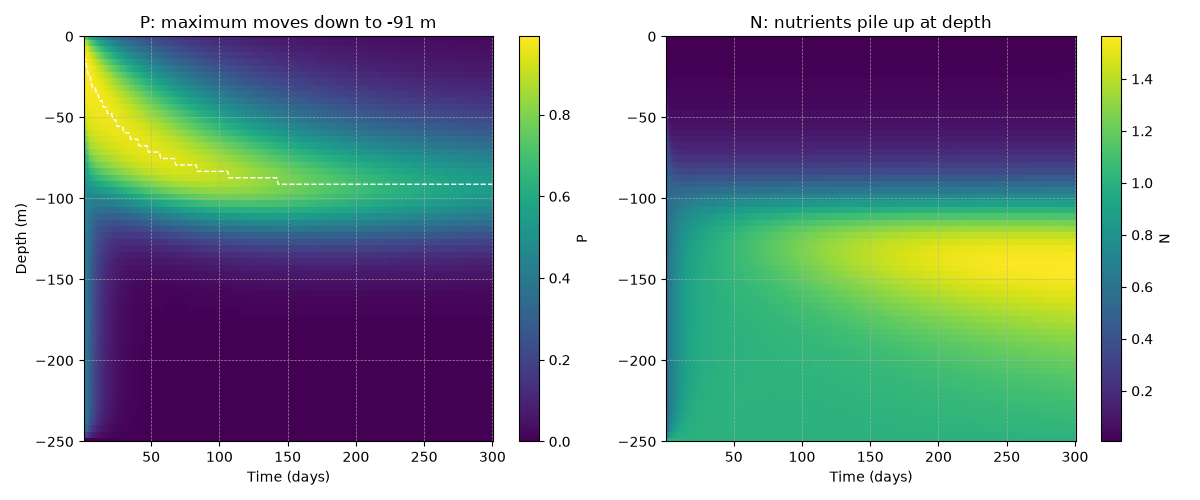

In [20]:
max_day = 300
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plots.hovmoller(sink, "P", zmin=-150, max_day=max_day, fig=fig, ax=ax[0])
d, v = dcm(sink)
ax[0].plot(sink.days[:max_day], d[:max_day], "w--", lw=1)      # depth of the maximum
ax[0].set_title(f"P: maximum moves down to {d[max_day - 1]:.0f} m")
plots.hovmoller(sink, "N", zmin=-250, max_day=max_day, fig=fig, ax=ax[1])
ax[1].set_title("N: nutrients pile up at depth")
for a in ax:
    a.set_yticks(np.arange(0, -251, -50))
    a.grid(True, linestyle="--", alpha=0.8)
ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

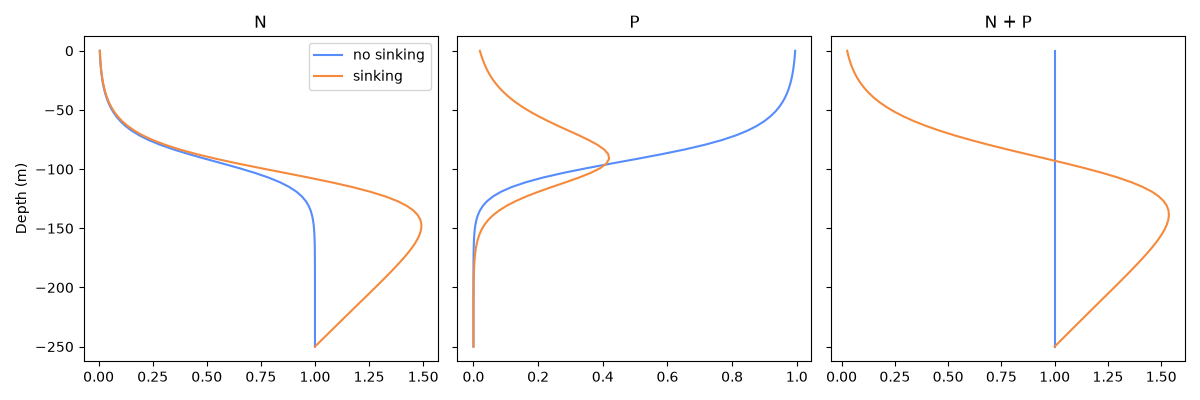

In [21]:
fig, ax = plt.subplots(1, 3, sharey=True, figsize=(12, 4))
for res, name in ((base, "no sinking"), (sink, "sinking")):
    ax[0].plot(res.N[-1], res.depth, label=name)
    ax[1].plot(res.P[-1], res.depth, label=name)
    ax[2].plot(res.N[-1] + res.P[-1], res.depth, label=name)
ax[0].set_title("N"); ax[1].set_title("P"); ax[2].set_title("N + P")
ax[0].set_ylabel("Depth (m)"); ax[0].legend()
plt.tight_layout()
plt.show()

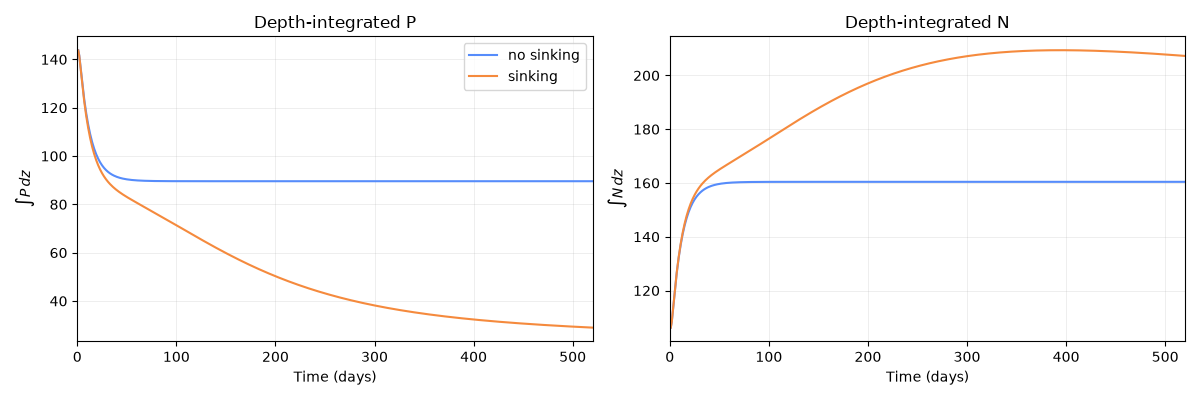

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for res, name in ((base, "no sinking"), (sink, "sinking")):
    ax[0].plot(res.days, trapz(res.P, res.depth, axis=1), label=name)
    ax[1].plot(res.days, trapz(res.N, res.depth, axis=1), label=name)
ax[0].set(title="Depth-integrated P", xlabel="Time (days)", ylabel=r"$\int P\,dz$")
ax[1].set(title="Depth-integrated N", xlabel="Time (days)", ylabel=r"$\int N\,dz$")
for a in ax:
    a.set_xlim(0, min(base.days[-1], sink.days[-1]))
    a.grid(alpha=0.3)
ax[0].legend()
plt.tight_layout()
plt.show()

**Takeaways**
- A deep biomass maximum forms at depth within the water column
- Phytoplankton sink and die at depth, which moves nutrients down faster than mixing brings them back
- Nutrients pile up at depth, and deplete at the surface
- $P$ cannot sink too much due to the light
- Sinking breaks $N+P=1$; surface becomes inactive with $N$ or $P$

### Self-Shading by Phytoplankton

When phytoplankton stack on top of each other vertically, the deeper regions receive less light than shallower regions. This **self-shading** effect compounds the background exponential decay of light intensity in water according to the Beer-Lambert Law.

Recall, the 'growth' term includes an exponential light-decay factor:
$$
\begin{align}
\mu(N,P,z) = GNPe^{Kz} - DP.
\end{align}
$$
So far, we have considered $K$ to be constant. To model self-shading, we let $K$ depend on the phytoplankton concentration $P(z)$ in two ways:

#### 1. Local (Levy, 2015)
The first one applies local attenuation
$$
\begin{align}
K = K_0 + K_s P(z),
\end{align}
$$
where $K_0$ is the background water attenuation coefficient used earlier, and $K_s$ is the specific attenuation due to phytoplankton. This assumes the water column above depth $z$ has a uniform concentration equal to $P(z)$.

#### 2. Integrated (Shigesada and Okubo, 1981)
In this case, we modify the attenuation in a similar way, but now we include the vertically integrated phytoplankton above each depth level,
$$
\begin{align}
K = K_0 + \frac{K_s}{|z|}\int_{z}^0 P(z')dz' = K_0 + K_s \bar{P}(z),
\end{align}
$$
where $\bar{P}(z)$ is the average phytoplankton concentration above depth $z$.


Option 2 is more physically correct. Option 1 is a common, cheaper approximation.

In [23]:
shade_local = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE="local", N_BOT_BC="dirichlet")
shade_integral = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE="integral", N_BOT_BC="dirichlet")

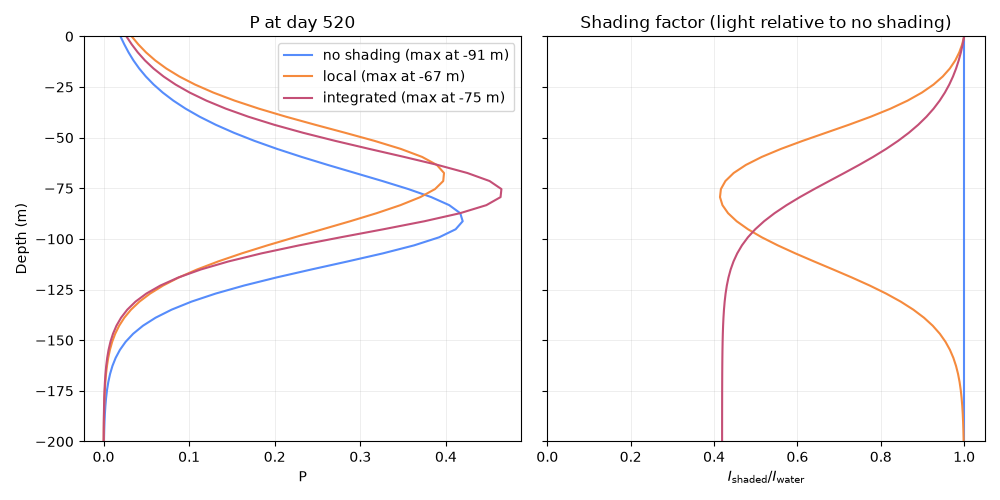

In [24]:
def light(res, mode=None, k=-1):
    z, P = res.depth, res.P[k]
    K0, Ks = params.LIGHT_ATTENUATION, params.SHADING_COEFF
    if mode == "local":
        return np.exp((K0 + Ks * P) * z)
    if mode == "integral":
        dz = z[1] - z[0]
        Pt = P[::-1]
        P_above = np.concatenate(([0.0], np.cumsum(0.5 * (Pt[1:] + Pt[:-1]) * dz)))[::-1]
        return np.exp(K0 * z - Ks * P_above)
    return np.exp(K0 * z)

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(10, 5))
for res, mode, name in ((sink, None, "no shading"), (shade_local, "local", "local"), (shade_integral, "integral", "integrated")):
    d, v = dcm(res)
    line, = ax[0].plot(res.P[-1], res.depth, label=f"{name} (max at {d[-1]:.0f} m)")
    ax[1].plot(light(res, mode) / np.exp(params.LIGHT_ATTENUATION * res.depth), res.depth, color=line.get_color(), label=name)
ax[0].set(title=f"P at day {sink.days[-1]:.0f}", xlabel="P", ylabel="Depth (m)", ylim=(-200, 0)); ax[0].legend()
ax[1].set(title="Shading factor (light relative to no shading)", xlabel=r"$I_{\rm shaded}/I_{\rm water}$", xlim=(0, 1.05))
for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Takeaways**
- Shading makes light fade faster with depth (as expected)
- Local method overestimates shading effect.

### Forcing N

Finally, we want to investigate what happens when the nutrient flux at the surface is forced by some external agent. These situations can arise in real life due to various factors, such as river runoff (occurs seasonally), storm surges, or eutrophication. Below, we show different scenarios of nutrient flux forcings:

- Unforced / Constant: There is a constant addition of nutrients at the surface.
- Seasonal: The flux increases in the summer months once annually, modeling river runoff effects.
- Storm Pulse: A large influx of nutrients in a short time due storms.
- Eutrophication: The seasonal increase in the summer months but, this gets larger every year due to recycling of nutrients and depleted oxygen at the bottom.

In [25]:
F_REF = 1e-4 * 0.05                       # KAPPA * LIGHT_ATTENUATION (m s^-1 in nutrient units)
long = dict(DEPTH=500, NZ=127, T_END_DAYS=3 * 365, SAVE_EVERY_DAYS=5, SINKING_ENABLED=True, N_BOT_BC="dirichlet")

runs = {
    "unforced":             sim.run(**long),
    "constant":             sim.run(SURFACE_FLUX=constant(0.2*F_REF), **long),
    "seasonal flux":        sim.run(SURFACE_FLUX=seasonal_flux(0.2*F_REF, 0.2*F_REF), **long),
    "storm pulses":         sim.run(SURFACE_FLUX=pulses([100, 300, 500, 700], 1e-5, 2.0), **long),
    "eutrophication trend": sim.run(SURFACE_FLUX=add(seasonal_flux(0.2*F_REF, 0.2*F_REF), ramp(365, 1095, 0, 0.2*F_REF)), **long),
}

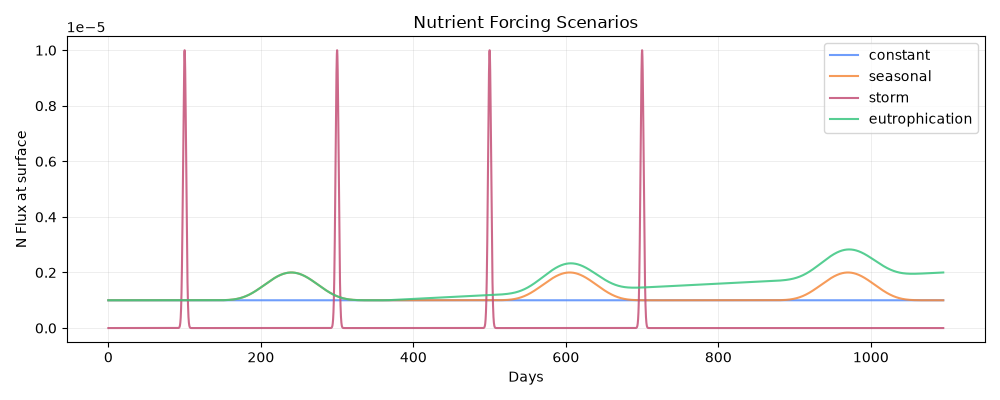

In [26]:
fig, ax = plt.subplots(figsize=(10, 4))

funcs = {
    "constant":       constant(0.2 * F_REF),
    "seasonal":       seasonal_flux(0.2 * F_REF, 0.2 * F_REF),
    "storm":          pulses([100, 300, 500, 700], 1e-5, 2.0),
    "eutrophication": add(seasonal_flux(0.2 * F_REF, 0.2 * F_REF), ramp(365, 1095, 0, 0.2 * F_REF)),
}

times = np.arange(0, 365 * 3 * 86400, 3600)
days = times / 86400

for name, func in funcs.items():
    flux = np.array([func(t) for t in times])
    ax.plot(days, flux, label=name, alpha=0.85)

ax.set_xlabel("Days")
ax.set_ylabel("N Flux at surface")
ax.set_title("Nutrient Forcing Scenarios")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

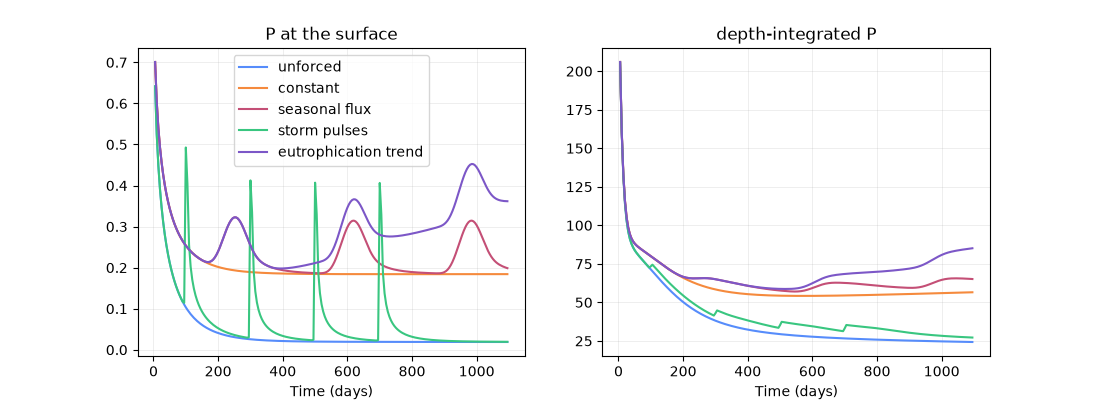

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, res in runs.items():
    ax[0].plot(res.days, res.P[:, -1], label=name)                 # surface P
    ax[1].plot(res.days, trapz(res.P, res.depth, axis=1), label=name)
ax[0].set_title("P at the surface"); ax[1].set_title("depth-integrated P")
for a in ax: a.set_xlabel("Time (days)"); a.grid(True, alpha=.3)
ax[0].legend()
plt.show()

In [28]:
times = np.arange(0, 365*3*86400, 1000)
func = pulses([100, 300, 500, 700], 1e-5, 2.0)
seasonal = func(t)
print(func(t))
plt.figure()
# plt.plot(t, seasonal)
plt.show()

NameError: name 't' is not defined

In [ ]:
func(t)

In [ ]:
t.shape